# Optimización definitiva de Crop2 y Crop3

Fashion-MNIST se ejecuta primero y MNIST después. Para cada dataset se maximiza primero `acc_both` y luego `ssim`. Cada bloque ejecuta los dos estudios, genera sus gráficos de cortes (*slice plots*) y compara los modelos con sus mejores parámetros.

Los estudios usan 100 pruebas, 1.000 mezclas de entrenamiento fijas y 30 iteraciones por prueba. Optuna, la selección del lote de entrenamiento y la evaluación de cada prueba usan la semilla 3333. La comparación usa 10 lotes de prueba de 1.000 mezclas y 50 iteraciones. Cada par de modelos recibe el mismo lote y la misma semilla de evaluación.

Los estudios SQLite, los datos por corrida y los PNG de las comparaciones se guardan en `results/<dataset>/<objetivo>/`, junto a este notebook. Los gr?ficos de cortes son interactivos y se muestran dentro del notebook. Para regenerar figuras a partir de los archivos, ejecutá las celdas de configuración y funciones, saltá los cuatro bloques de ejecución y usá la sección final.

## Configuración y evaluación

In [1]:
from pathlib import Path
from tempfile import NamedTemporaryFile
import json
import sys

import numpy as np
import optuna

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "project" / "CROP" / "models").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Abrí el notebook desde el repositorio.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RESULTS_DIR = PROJECT_ROOT / "project" / "definitive_experiments" / "results"
SEED = 3333
LAT, INTER = 64, 256
N_IMAGES = 1000
N_TRIALS = 100
STUDY_ITERATIONS = 30
N_RUNS = 10
COMPARISON_ITERATIONS = 50

DATASETS = {"fashion": "Fashion-MNIST", "mnist": "MNIST"}
SEARCH_PARAMS = {"Crop2": ("gamma",), "Crop3": ("gamma", "delta")}
SEARCH_BOUNDS = (float(np.nextafter(0.0, 2.0)), float(np.nextafter(2.0, 0.0)))
FIXED_PARAMS = {"alpha_1": -2, "alpha_2": -22, "bias": 0.22, "slope": 22,
                "alpha_mix": 0.5, "beta": 1}
CURVE_KEYS = {"acc_both": "acc_both_plot", "ssim": "ssim_plot", "psnr": "psnr_plot"}


def result_dir(dataset, objective_metric):
    return RESULTS_DIR / dataset / objective_metric


def load_inputs(dataset):
    import tensorflow as tf
    from project.CROP.models.crop2 import Crop2
    from project.CROP.models.crop3 import Crop3
    from project.loader import Loader

    tf.keras.utils.set_random_seed(SEED)
    return (
        Loader.data(dataset),
        Loader.cvae(model_name=f"int_{INTER}_lat_{LAT}_{dataset}.keras"),
        Loader.predictor(dataset=dataset),
        {"Crop2": Crop2, "Crop3": Crop3},
    )


def sample_batch(data, split, seed):
    rng = np.random.default_rng(seed)
    x0, x1 = data[f"x_{split}"], data[f"x_{split}_1"]
    y0, y1 = data[f"y_{split}"], data[f"y_{split}_1"]
    idx0 = rng.choice(len(x0), size=N_IMAGES, replace=False)
    idx1 = rng.choice(len(x1), size=N_IMAGES, replace=False)
    return (x0[idx0], x1[idx1], y0[idx0], y1[idx1]), (idx0, idx1)


def evaluate(inputs, model_name, batch, tuned_params, seed, iterations, *, curves=False, show_image=False):
    import tensorflow as tf

    data, cvae, predictor, models = inputs
    tf.keras.utils.set_random_seed(seed)
    model = models[model_name](cvae=cvae, predictor=predictor)
    return model.unmix(
        *batch,
        params={**FIXED_PARAMS, **tuned_params},
        iterations=iterations,
        labels=data["labels"],
        show_image=show_image,
        show_metrics=False,
        save_all_curves=curves,
    )


def scalar_metric(metrics, key):
    value = metrics[key]
    return float(value[0] if isinstance(value, (tuple, list)) else value)

/home/galsan/venvs/tensorflow-gpu/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Estudios y gráficos de cortes

In [2]:
def study_location(dataset, objective_metric, model_name):
    path = result_dir(dataset, objective_metric) / f"{model_name}.sqlite3"
    name = f"{dataset}_{objective_metric}_{model_name}"
    return path, f"sqlite:///{path.as_posix()}", name


def load_study(dataset, objective_metric, model_name):
    path, storage, name = study_location(dataset, objective_metric, model_name)
    if not path.is_file():
        raise FileNotFoundError(f"No se encontró el estudio en {path}")
    return optuna.load_study(storage=storage, study_name=name)


def optimize_model(dataset, objective_metric, model_name, inputs, train_batch):
    path, storage, name = study_location(dataset, objective_metric, model_name)
    path.parent.mkdir(parents=True, exist_ok=True)
    study = optuna.create_study(
        storage=storage,
        study_name=name,
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEED),
        load_if_exists=True,
    )
    config = {
        "seed": SEED,
        "images": N_IMAGES,
        "iterations": STUDY_ITERATIONS,
        "latent_dim": LAT,
        "intermediate_dim": INTER,
        "fixed_params": FIXED_PARAMS,
        "search_params": list(SEARCH_PARAMS[model_name]),
        "bounds": list(SEARCH_BOUNDS),
    }
    saved_config = study.user_attrs.get("config")
    if saved_config is None and not study.get_trials(deepcopy=False):
        study.set_user_attr("config", config)
    elif saved_config != config:
        raise ValueError(f"La configuración guardada en {path} difiere de la actual.")

    def objective(trial):
        params = {
            key: trial.suggest_float(key, *SEARCH_BOUNDS)
            for key in SEARCH_PARAMS[model_name]
        }
        metrics = evaluate(inputs, model_name, train_batch, params, SEED, STUDY_ITERATIONS)
        score = scalar_metric(metrics, objective_metric)
        if not np.isfinite(score):
            raise ValueError(f"Métrica no finita en {name}: {score}")
        trial.set_user_attr("effective_params", {**FIXED_PARAMS, **params})
        for key in ("acc_both", "ssim", "recon_bpsnr"):
            value = scalar_metric(metrics, key)
            trial.set_user_attr(key, value if np.isfinite(value) else None)
        return score

    completed = study.get_trials(states=(optuna.trial.TrialState.COMPLETE,), deepcopy=False)
    remaining = max(0, N_TRIALS - len(completed))
    if remaining:
        study.optimize(objective, n_trials=remaining, n_jobs=1)

    print(f"{name} · {study.best_value:.6g} · {study.best_params}", flush=True)
    return study


def plot_study(study, dataset, objective_metric, model_name):
    from optuna.visualization import plot_slice

    fig = plot_slice(study, params=list(SEARCH_PARAMS[model_name]),
                     target_name=objective_metric)
    fig.update_layout(title=f"{DATASETS[dataset]} ? {model_name} ? {objective_metric}")
    fig.show()

## Comparaciones y gráficos

In [3]:
def comparison_config(studies):
    configs = {model: study.user_attrs["config"] for model, study in studies.items()}
    return {
        "seed": SEED,
        "runs": N_RUNS,
        "images": N_IMAGES,
        "iterations": COMPARISON_ITERATIONS,
        "study_configs": configs,
        "best_trials": {model: study.best_trial.number for model, study in studies.items()},
        "best_params": {model: study.best_params for model, study in studies.items()},
    }


def comparison_dir(dataset, objective_metric, config):
    trials = config["best_trials"]
    return result_dir(dataset, objective_metric) / (
        f"comparison_Crop2_{trials['Crop2']}_Crop3_{trials['Crop3']}"
    )


def read_comparison_run(path, config):
    with np.load(path, allow_pickle=False) as saved:
        if json.loads(saved["config"].item()) != config:
            raise ValueError(f"La configuración guardada en {path} difiere de la actual.")
        return {
            model: {metric: saved[f"{model}_{metric}"] for metric in CURVE_KEYS}
            for model in config["best_params"]
        }


def load_comparison(dataset, objective_metric, studies):
    config = comparison_config(studies)
    folder = comparison_dir(dataset, objective_metric, config)
    runs = [
        read_comparison_run(folder / f"run_{run:02d}.npz", config)
        for run in range(1, config["runs"] + 1)
    ]
    curves = {
        model: {metric: np.stack([run[model][metric] for run in runs])
                for metric in CURVE_KEYS}
        for model in config["best_params"]
    }
    return config, curves


def run_comparison(dataset, objective_metric, studies, inputs):
    config = comparison_config(studies)
    folder = comparison_dir(dataset, objective_metric, config)
    folder.mkdir(parents=True, exist_ok=True)
    seeds = np.random.SeedSequence(config["seed"]).generate_state(config["runs"])
    for run, seed in enumerate(seeds, start=1):
        path = folder / f"run_{run:02d}.npz"
        if path.is_file():
            read_comparison_run(path, config)
            continue

        seed = int(seed)
        print(f"{DATASETS[dataset]} · {objective_metric} · corrida {run}/{config['runs']}",
              flush=True)
        batch, (idx0, idx1) = sample_batch(inputs[0], "test", seed)
        arrays = {
            "config": json.dumps(config),
            "seed": seed,
            "source1_indices": idx0,
            "source2_indices": idx1,
        }
        for model, params in config["best_params"].items():
            metrics = evaluate(inputs, model, batch, params, seed, config["iterations"],
                               curves=True)
            for metric, key in CURVE_KEYS.items():
                arrays[f"{model}_{metric}"] = np.asarray(metrics[key], dtype=float)

        # Publicar la corrida solo después de guardar los resultados de ambos modelos.
        with NamedTemporaryFile(dir=folder, suffix=".tmp", delete=False) as temporary:
            temp_path = Path(temporary.name)
            try:
                np.savez_compressed(temporary, **arrays)
                temporary.close()
                temp_path.replace(path)
            finally:
                temporary.close()
                temp_path.unlink(missing_ok=True)

In [4]:
def plot_comparison(dataset, objective_metric, config, curves):
    import matplotlib.pyplot as plt

    folder = comparison_dir(dataset, objective_metric, config)
    footer = "\n".join(
        f"{model} · " + " | ".join(f"{name} = {value:.10g}" for name, value in params.items())
        for model, params in config["best_params"].items()
    )
    labels = {
        "acc_both": ("Exactitud de ambas fuentes", "Exactitud [%]", 100),
        "ssim": ("SSIM", "SSIM", 1),
        "psnr": ("PSNR", "PSNR [dB]", 1),
    }
    for metric, (title, ylabel, scale) in labels.items():
        fig, ax = plt.subplots(figsize=(9, 6))
        for model, model_curves in curves.items():
            values = model_curves[metric] * scale
            mean, std = values.mean(axis=0), values.std(axis=0)
            iterations = np.arange(1, len(mean) + 1)
            line, = ax.plot(iterations, mean, label=model)
            ax.fill_between(iterations, mean - std, mean + std,
                            color=line.get_color(), alpha=0.2)

        ax.set_title(
            f"{DATASETS[dataset]} · {title} · {config['runs']} corridas\n"
            f"Parámetros optimizados con {objective_metric}"
        )
        ax.set_xlabel("Iteración")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        ax.legend()
        fig.text(0.5, 0.02, footer, ha="center", va="bottom")
        fig.tight_layout(rect=(0, 0.12, 1, 1))
        fig.savefig(folder / f"{metric}.png", dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(fig)


def run_experiment(dataset, objective_metric):
    inputs = load_inputs(dataset)
    train_batch, _ = sample_batch(inputs[0], "train", SEED)
    studies = {}
    for model in SEARCH_PARAMS:
        study = optimize_model(dataset, objective_metric, model, inputs, train_batch)
        plot_study(study, dataset, objective_metric, model)
        studies[model] = study

    run_comparison(dataset, objective_metric, studies, inputs)
    plot_comparison(dataset, objective_metric,
                    *load_comparison(dataset, objective_metric, studies))

## Fashion-MNIST

I0000 00:00:1795578658.659472  121660 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795578658.810613  121660 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795578660.663690  121660 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Usando fashion como dataset


I0000 00:00:1795578662.197485  121660 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9534 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3080 Ti, pci bus id: 0000:01:00.0, compute capability: 8.6
[I 2026-11-25 00:51:04,355] A new study created in RDB with name: fashion_acc_both_Crop2
I0000 00:00:1795578665.096206  121660 cuda_dnn.cc:461] Loaded cuDNN version 92801
[I 2026-11-25 00:51:08,632] Trial 0 finished with value: 0.451 and parameters: {'gamma': 1.5031512144089572}. Best is trial 0 with value: 0.451.
[I 2026-11-25 00:51:10,143] Trial 1 finished with value: 0.631 and parameters: {'gamma': 0.21850255077708544}. Best is trial 1 with value: 0.631.
[I 2026-11-25 00:51:11,642] Trial 2 finished with value: 0.58 and parameters: {'gamma': 0.9722425581148703}. Best is trial 1 with value: 0.631.
[I 2026-11-25 00:51:13,268] Trial 3 finished with value: 0.579 and parameters: {'gamma': 0.9996623554960683}. Best is trial 1 with value: 0.631.
[I 2026-11-

fashion_acc_both_Crop2 · 0.641 · {'gamma': 0.17334894739230727}


[I 2026-11-25 00:53:49,257] A new study created in RDB with name: fashion_acc_both_Crop3
[I 2026-11-25 00:53:50,896] Trial 0 finished with value: 0.429 and parameters: {'gamma': 1.5031512144089572, 'delta': 0.21850255077708544}. Best is trial 0 with value: 0.429.
[I 2026-11-25 00:53:52,438] Trial 1 finished with value: 0.446 and parameters: {'gamma': 0.9722425581148703, 'delta': 0.9996623554960683}. Best is trial 1 with value: 0.446.
[I 2026-11-25 00:53:54,104] Trial 2 finished with value: 0.436 and parameters: {'gamma': 1.3142199980396863, 'delta': 0.47176942248161374}. Best is trial 1 with value: 0.446.
[I 2026-11-25 00:53:55,789] Trial 3 finished with value: 0.483 and parameters: {'gamma': 1.225589781321188, 'delta': 0.23930480679487684}. Best is trial 3 with value: 0.483.
[I 2026-11-25 00:53:57,663] Trial 4 finished with value: 0.376 and parameters: {'gamma': 1.424404593266756, 'delta': 0.7451210841006556}. Best is trial 3 with value: 0.483.
[I 2026-11-25 00:53:59,355] Trial 5 fini

fashion_acc_both_Crop3 · 0.648 · {'gamma': 0.10581787244867041, 'delta': 0.25409356231336455}


Fashion-MNIST · acc_both · corrida 1/10
Fashion-MNIST · acc_both · corrida 2/10
Fashion-MNIST · acc_both · corrida 3/10
Fashion-MNIST · acc_both · corrida 4/10
Fashion-MNIST · acc_both · corrida 5/10
Fashion-MNIST · acc_both · corrida 6/10
Fashion-MNIST · acc_both · corrida 7/10
Fashion-MNIST · acc_both · corrida 8/10
Fashion-MNIST · acc_both · corrida 9/10
Fashion-MNIST · acc_both · corrida 10/10


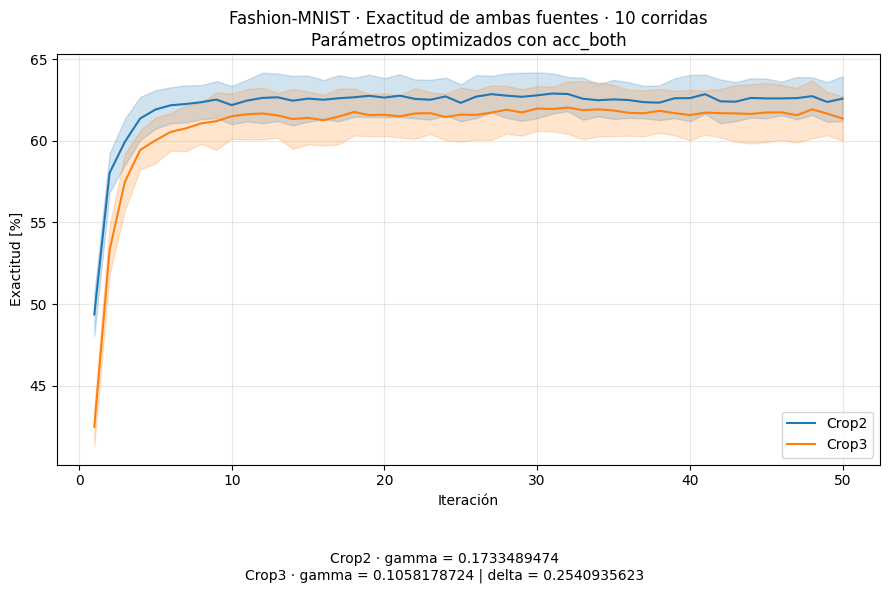

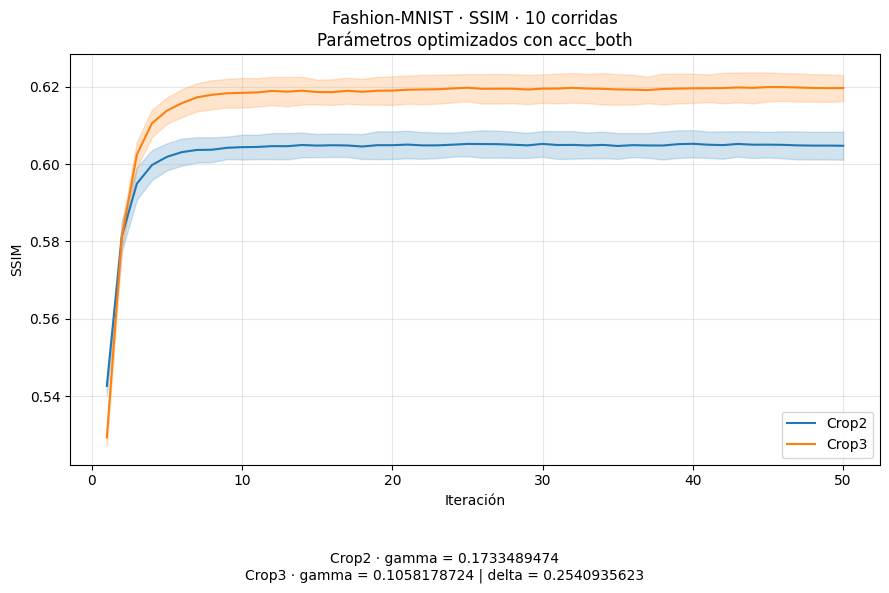

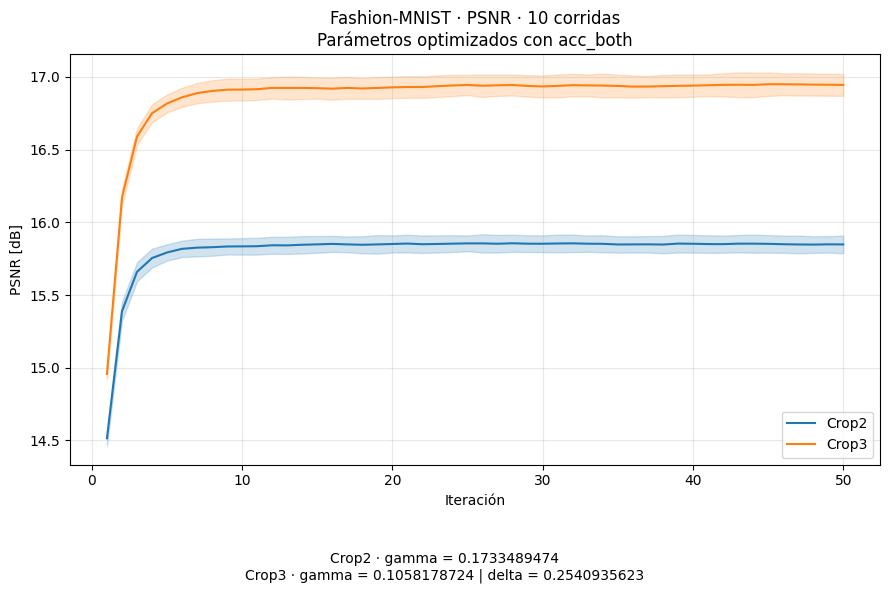

In [5]:
run_experiment("fashion", "acc_both")

Usando fashion como dataset


[I 2026-11-25 01:02:04,946] A new study created in RDB with name: fashion_ssim_Crop2
[I 2026-11-25 01:02:06,603] Trial 0 finished with value: 0.6339446902275085 and parameters: {'gamma': 1.5031512144089572}. Best is trial 0 with value: 0.6339446902275085.
[I 2026-11-25 01:02:08,297] Trial 1 finished with value: 0.6103523373603821 and parameters: {'gamma': 0.21850255077708544}. Best is trial 0 with value: 0.6339446902275085.
[I 2026-11-25 01:02:09,865] Trial 2 finished with value: 0.6538065671920776 and parameters: {'gamma': 0.9722425581148703}. Best is trial 2 with value: 0.6538065671920776.
[I 2026-11-25 01:02:11,379] Trial 3 finished with value: 0.6542739868164062 and parameters: {'gamma': 0.9996623554960683}. Best is trial 3 with value: 0.6542739868164062.
[I 2026-11-25 01:02:12,894] Trial 4 finished with value: 0.6431067585945129 and parameters: {'gamma': 1.3142199980396863}. Best is trial 3 with value: 0.6542739868164062.
[I 2026-11-25 01:02:14,754] Trial 5 finished with value: 0.

fashion_ssim_Crop2 · 0.654274 · {'gamma': 0.9996623554960683}


[I 2026-11-25 01:04:41,316] A new study created in RDB with name: fashion_ssim_Crop3
[I 2026-11-25 01:04:42,274] Trial 0 finished with value: 0.6327145099639893 and parameters: {'gamma': 1.5031512144089572, 'delta': 0.21850255077708544}. Best is trial 0 with value: 0.6327145099639893.
[I 2026-11-25 01:04:43,927] Trial 1 finished with value: 0.602339506149292 and parameters: {'gamma': 0.9722425581148703, 'delta': 0.9996623554960683}. Best is trial 0 with value: 0.6327145099639893.
[I 2026-11-25 01:04:45,563] Trial 2 finished with value: 0.6343225240707397 and parameters: {'gamma': 1.3142199980396863, 'delta': 0.47176942248161374}. Best is trial 2 with value: 0.6343225240707397.
[I 2026-11-25 01:04:47,455] Trial 3 finished with value: 0.6466373801231384 and parameters: {'gamma': 1.225589781321188, 'delta': 0.23930480679487684}. Best is trial 3 with value: 0.6466373801231384.
[I 2026-11-25 01:04:49,159] Trial 4 finished with value: 0.6152133941650391 and parameters: {'gamma': 1.4244045932

fashion_ssim_Crop3 · 0.657801 · {'gamma': 0.9024900203890207, 'delta': 0.1007245195505777}


Fashion-MNIST · ssim · corrida 1/10
Fashion-MNIST · ssim · corrida 2/10
Fashion-MNIST · ssim · corrida 3/10
Fashion-MNIST · ssim · corrida 4/10
Fashion-MNIST · ssim · corrida 5/10
Fashion-MNIST · ssim · corrida 6/10
Fashion-MNIST · ssim · corrida 7/10
Fashion-MNIST · ssim · corrida 8/10
Fashion-MNIST · ssim · corrida 9/10
Fashion-MNIST · ssim · corrida 10/10


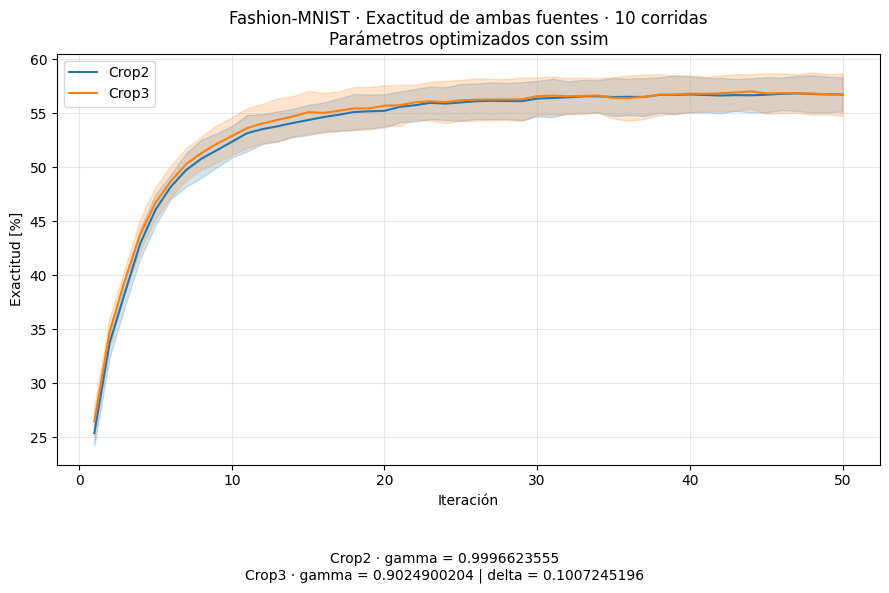

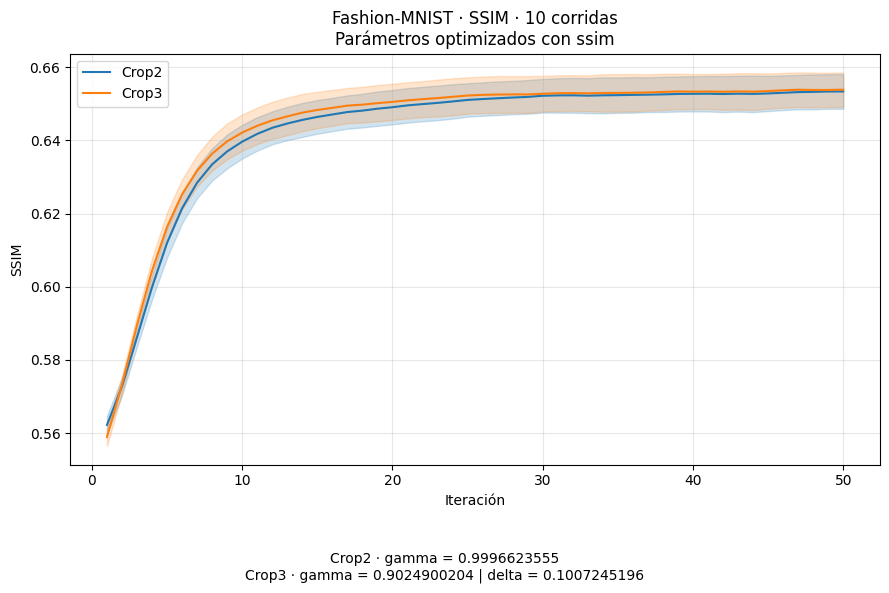

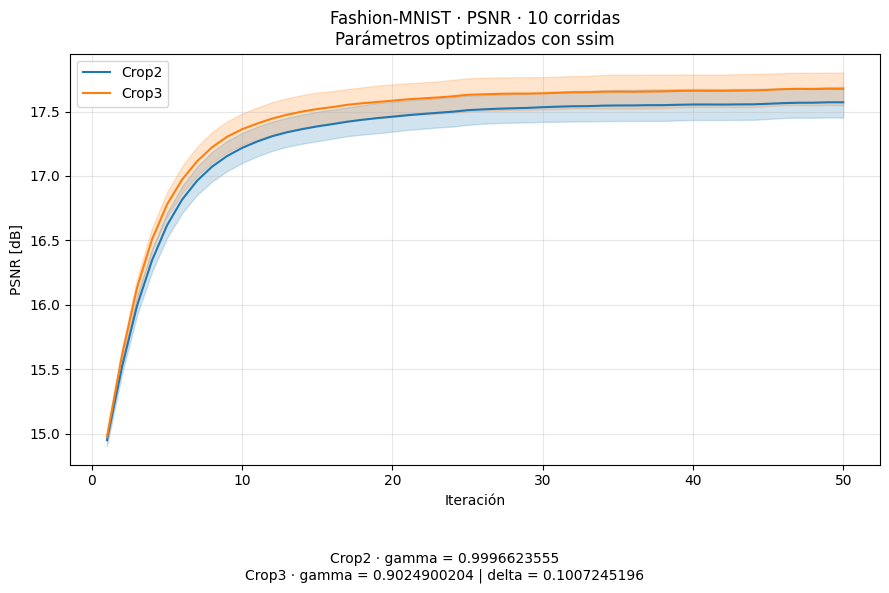

In [6]:
run_experiment("fashion", "ssim")

## MNIST

Usando mnist como dataset


[I 2026-11-25 01:12:58,686] A new study created in RDB with name: mnist_acc_both_Crop2
[I 2026-11-25 01:13:00,431] Trial 0 finished with value: 0.78 and parameters: {'gamma': 1.5031512144089572}. Best is trial 0 with value: 0.78.
[I 2026-11-25 01:13:01,997] Trial 1 finished with value: 0.874 and parameters: {'gamma': 0.21850255077708544}. Best is trial 1 with value: 0.874.
[I 2026-11-25 01:13:03,432] Trial 2 finished with value: 0.868 and parameters: {'gamma': 0.9722425581148703}. Best is trial 1 with value: 0.874.
[I 2026-11-25 01:13:05,119] Trial 3 finished with value: 0.864 and parameters: {'gamma': 0.9996623554960683}. Best is trial 1 with value: 0.874.
[I 2026-11-25 01:13:06,696] Trial 4 finished with value: 0.826 and parameters: {'gamma': 1.3142199980396863}. Best is trial 1 with value: 0.874.
[I 2026-11-25 01:13:08,284] Trial 5 finished with value: 0.884 and parameters: {'gamma': 0.47176942248161374}. Best is trial 5 with value: 0.884.
[I 2026-11-25 01:13:09,869] Trial 6 finishe

mnist_acc_both_Crop2 · 0.886 · {'gamma': 0.42044225659518675}


[I 2026-11-25 01:15:29,187] A new study created in RDB with name: mnist_acc_both_Crop3
[I 2026-11-25 01:15:30,740] Trial 0 finished with value: 0.763 and parameters: {'gamma': 1.5031512144089572, 'delta': 0.21850255077708544}. Best is trial 0 with value: 0.763.
[I 2026-11-25 01:15:32,285] Trial 1 finished with value: 0.737 and parameters: {'gamma': 0.9722425581148703, 'delta': 0.9996623554960683}. Best is trial 0 with value: 0.763.
[I 2026-11-25 01:15:33,824] Trial 2 finished with value: 0.785 and parameters: {'gamma': 1.3142199980396863, 'delta': 0.47176942248161374}. Best is trial 2 with value: 0.785.
[I 2026-11-25 01:15:35,317] Trial 3 finished with value: 0.824 and parameters: {'gamma': 1.225589781321188, 'delta': 0.23930480679487684}. Best is trial 3 with value: 0.824.
[I 2026-11-25 01:15:36,806] Trial 4 finished with value: 0.719 and parameters: {'gamma': 1.424404593266756, 'delta': 0.7451210841006556}. Best is trial 3 with value: 0.824.
[I 2026-11-25 01:15:38,423] Trial 5 finish

mnist_acc_both_Crop3 · 0.889 · {'gamma': 0.44595454347880914, 'delta': 0.12403531470477633}


MNIST · acc_both · corrida 1/10
MNIST · acc_both · corrida 2/10
MNIST · acc_both · corrida 3/10
MNIST · acc_both · corrida 4/10
MNIST · acc_both · corrida 5/10
MNIST · acc_both · corrida 6/10
MNIST · acc_both · corrida 7/10
MNIST · acc_both · corrida 8/10
MNIST · acc_both · corrida 9/10
MNIST · acc_both · corrida 10/10


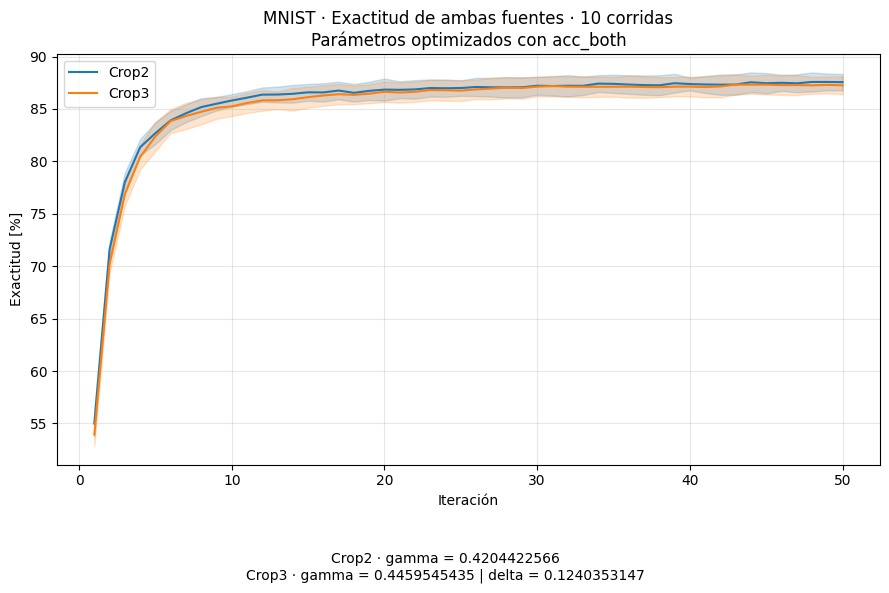

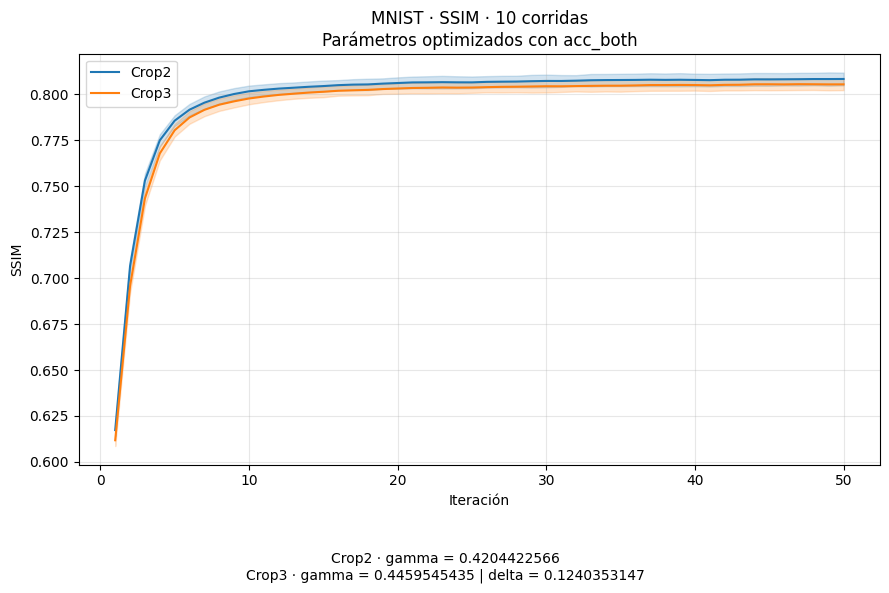

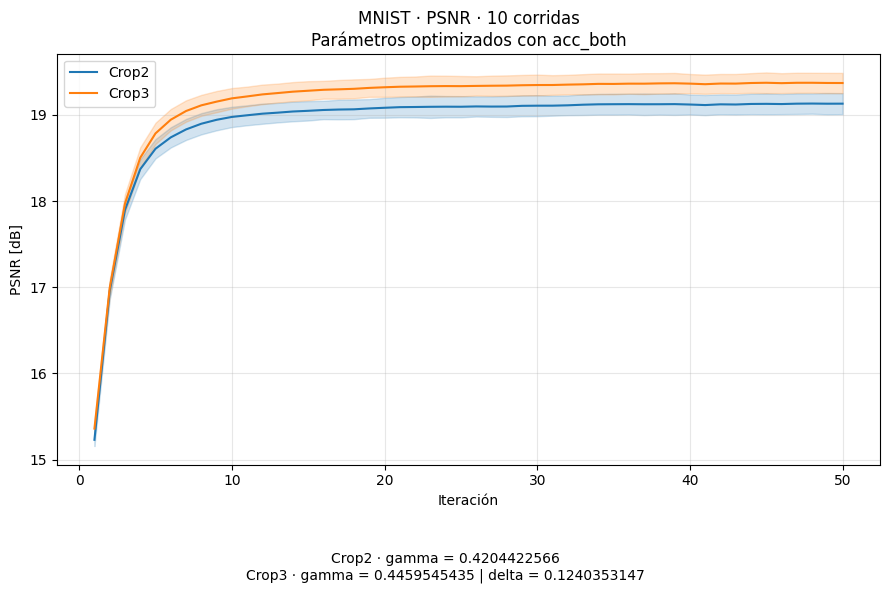

In [7]:
run_experiment("mnist", "acc_both")

Usando mnist como dataset


[I 2026-11-25 01:23:52,228] A new study created in RDB with name: mnist_ssim_Crop2
[I 2026-11-25 01:23:54,042] Trial 0 finished with value: 0.7919933795928955 and parameters: {'gamma': 1.5031512144089572}. Best is trial 0 with value: 0.7919933795928955.
[I 2026-11-25 01:23:55,092] Trial 1 finished with value: 0.8042522668838501 and parameters: {'gamma': 0.21850255077708544}. Best is trial 1 with value: 0.8042522668838501.
[I 2026-11-25 01:23:56,839] Trial 2 finished with value: 0.8138772249221802 and parameters: {'gamma': 0.9722425581148703}. Best is trial 2 with value: 0.8138772249221802.
[I 2026-11-25 01:23:58,574] Trial 3 finished with value: 0.8126824498176575 and parameters: {'gamma': 0.9996623554960683}. Best is trial 2 with value: 0.8138772249221802.
[I 2026-11-25 01:24:00,184] Trial 4 finished with value: 0.8045076131820679 and parameters: {'gamma': 1.3142199980396863}. Best is trial 2 with value: 0.8138772249221802.
[I 2026-11-25 01:24:01,870] Trial 5 finished with value: 0.81

mnist_ssim_Crop2 · 0.815302 · {'gamma': 0.8596278005733332}


[I 2026-11-25 01:26:33,661] A new study created in RDB with name: mnist_ssim_Crop3
[I 2026-11-25 01:26:35,410] Trial 0 finished with value: 0.7805014848709106 and parameters: {'gamma': 1.5031512144089572, 'delta': 0.21850255077708544}. Best is trial 0 with value: 0.7805014848709106.
[I 2026-11-25 01:26:37,161] Trial 1 finished with value: 0.7035723924636841 and parameters: {'gamma': 0.9722425581148703, 'delta': 0.9996623554960683}. Best is trial 0 with value: 0.7805014848709106.
[I 2026-11-25 01:26:38,849] Trial 2 finished with value: 0.7725534439086914 and parameters: {'gamma': 1.3142199980396863, 'delta': 0.47176942248161374}. Best is trial 0 with value: 0.7805014848709106.
[I 2026-11-25 01:26:40,459] Trial 3 finished with value: 0.7951591610908508 and parameters: {'gamma': 1.225589781321188, 'delta': 0.23930480679487684}. Best is trial 3 with value: 0.7951591610908508.
[I 2026-11-25 01:26:42,279] Trial 4 finished with value: 0.7359317541122437 and parameters: {'gamma': 1.42440459326

mnist_ssim_Crop3 · 0.815589 · {'gamma': 0.8346356182426254, 'delta': 0.0003793251702108938}


MNIST · ssim · corrida 1/10
MNIST · ssim · corrida 2/10
MNIST · ssim · corrida 3/10
MNIST · ssim · corrida 4/10
MNIST · ssim · corrida 5/10
MNIST · ssim · corrida 6/10
MNIST · ssim · corrida 7/10
MNIST · ssim · corrida 8/10
MNIST · ssim · corrida 9/10
MNIST · ssim · corrida 10/10


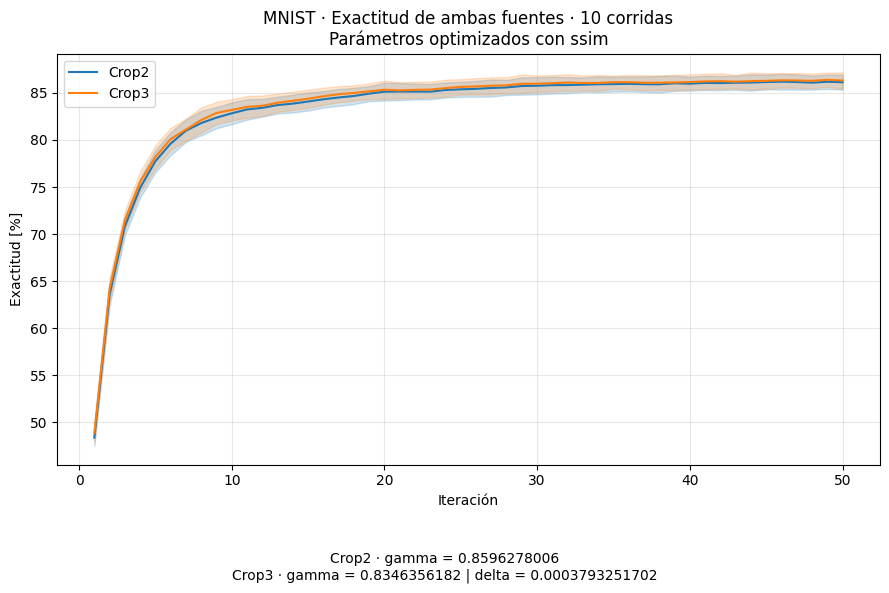

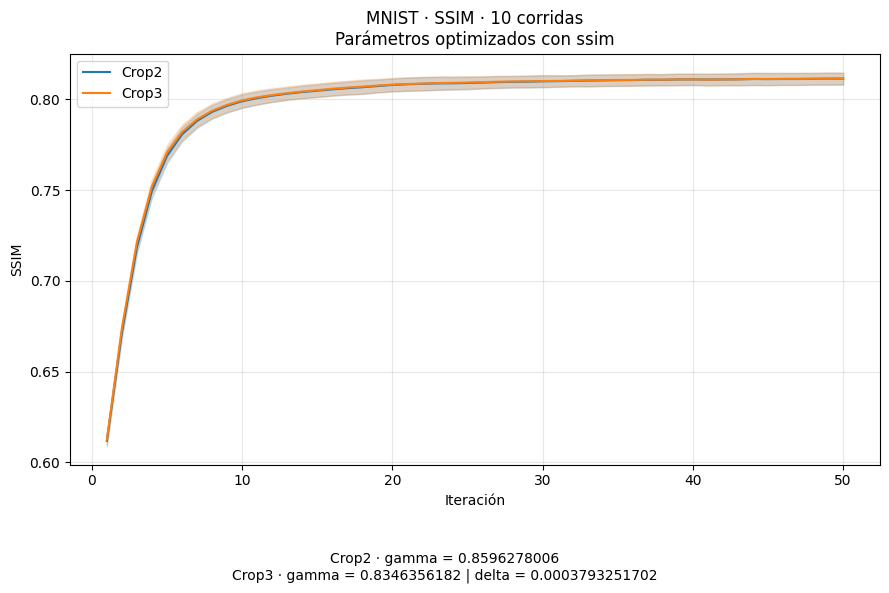

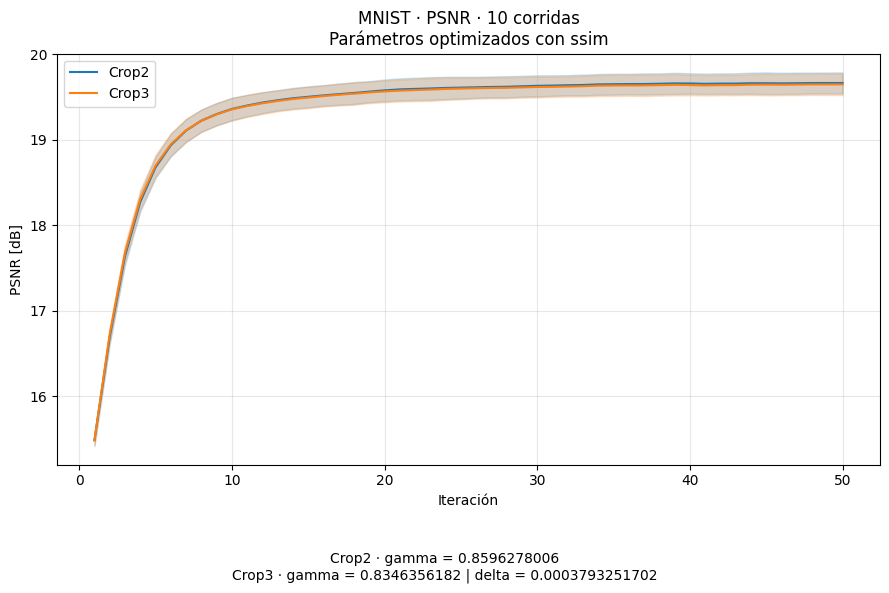

In [8]:
run_experiment("mnist", "ssim")

## Recuperar resultados guardados

Elegí el dataset y la métrica objetivo. Estas celdas cargan los estudios y las curvas por corrida desde disco, muestran los gr?ficos interactivos de Optuna y vuelven a guardar los PNG de las comparaciones. Las bandas de la comparación representan media ± un desvío estándar entre las 10 corridas.

In [9]:
dataset, objective_metric = "fashion", "acc_both"

saved_studies = {
    model: load_study(dataset, objective_metric, model)
    for model in SEARCH_PARAMS
}
for model, study in saved_studies.items():
    print(f"{model} · {study.best_value:.6g} · {study.best_params}")
    plot_study(study, dataset, objective_metric, model)

Crop2 · 0.641 · {'gamma': 0.17334894739230727}


Crop3 · 0.648 · {'gamma': 0.10581787244867041, 'delta': 0.25409356231336455}


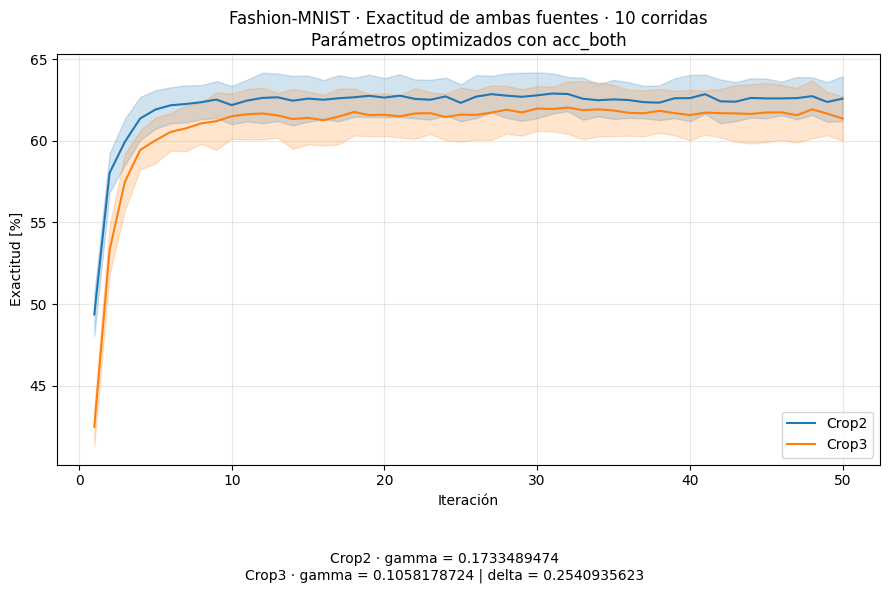

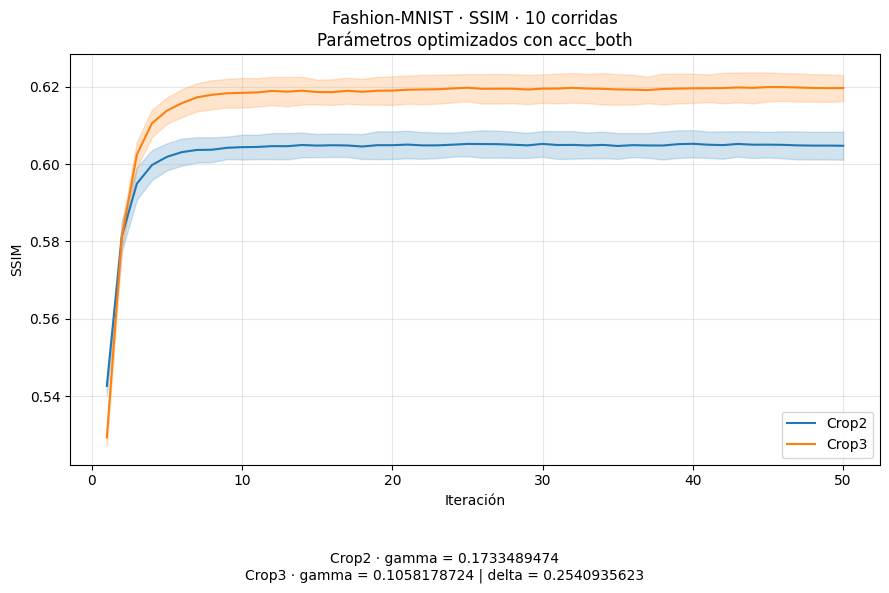

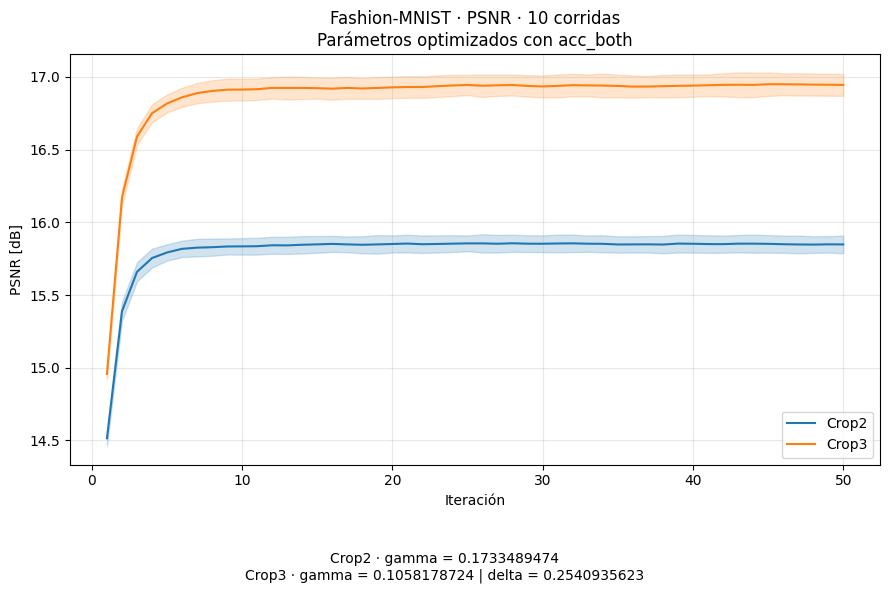

In [10]:
saved_config, saved_curves = load_comparison(dataset, objective_metric, saved_studies)
plot_comparison(dataset, objective_metric, saved_config, saved_curves)

## Separación visual con los mejores parámetros

Elegí el dataset y la métrica objetivo en la celda. Cada modelo separa las primeras 10 mezclas de prueba, como en `separation.ipynb`, con la semilla 3333 y 50 iteraciones. La figura muestra la mezcla, las fuentes originales y las estimaciones.

I0000 00:00:1795736531.172098  556777 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795736531.232869  556777 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795736533.590416  556777 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Usando fashion como dataset


I0000 00:00:1795736535.786866  556777 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3454 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3080 Ti, pci bus id: 0000:01:00.0, compute capability: 8.6


Fashion-MNIST · Crop2 · acc_both · {'gamma': 0.17334894739230727}


I0000 00:00:1795736539.174477  556777 cuda_dnn.cc:461] Loaded cuDNN version 92801


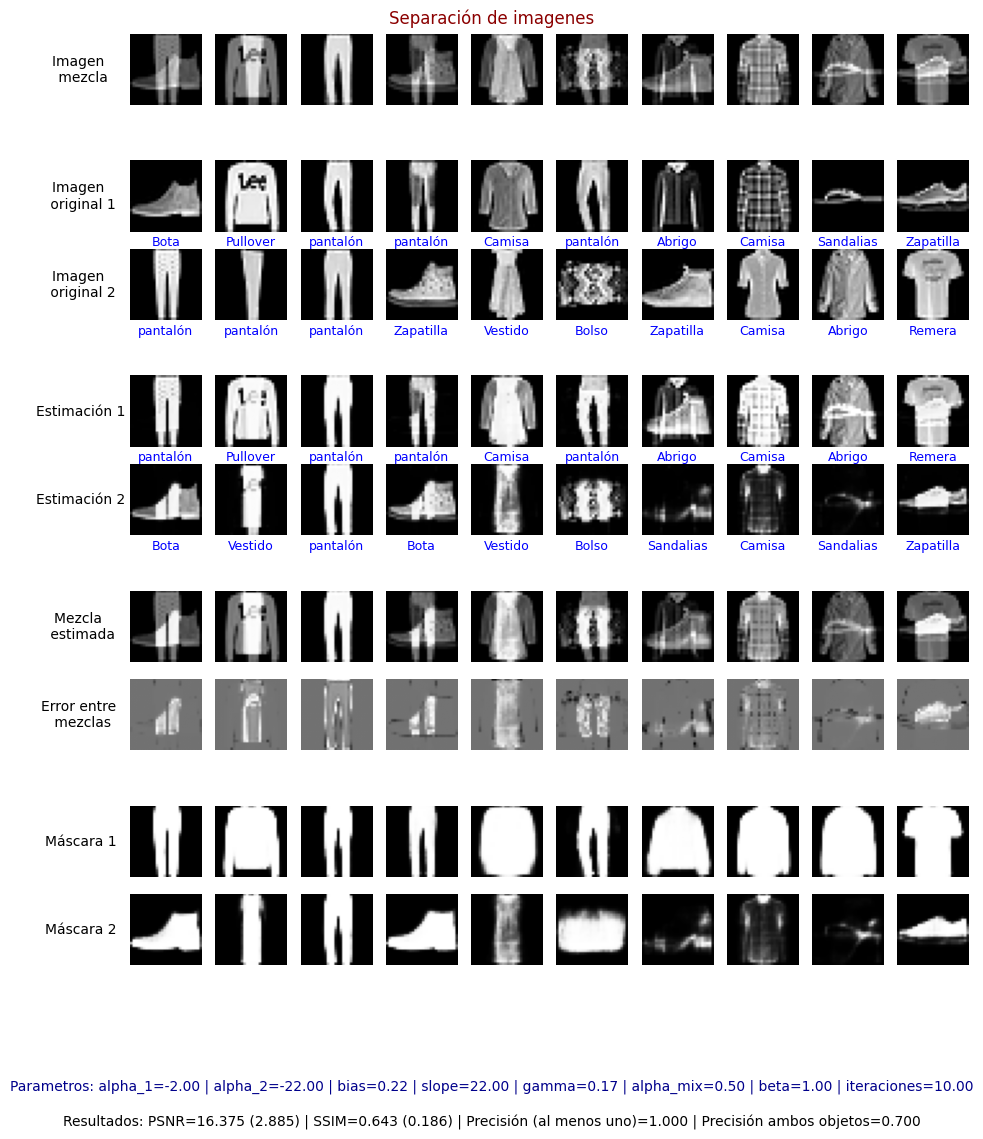

Fashion-MNIST · Crop3 · acc_both · {'gamma': 0.10581787244867041, 'delta': 0.25409356231336455}


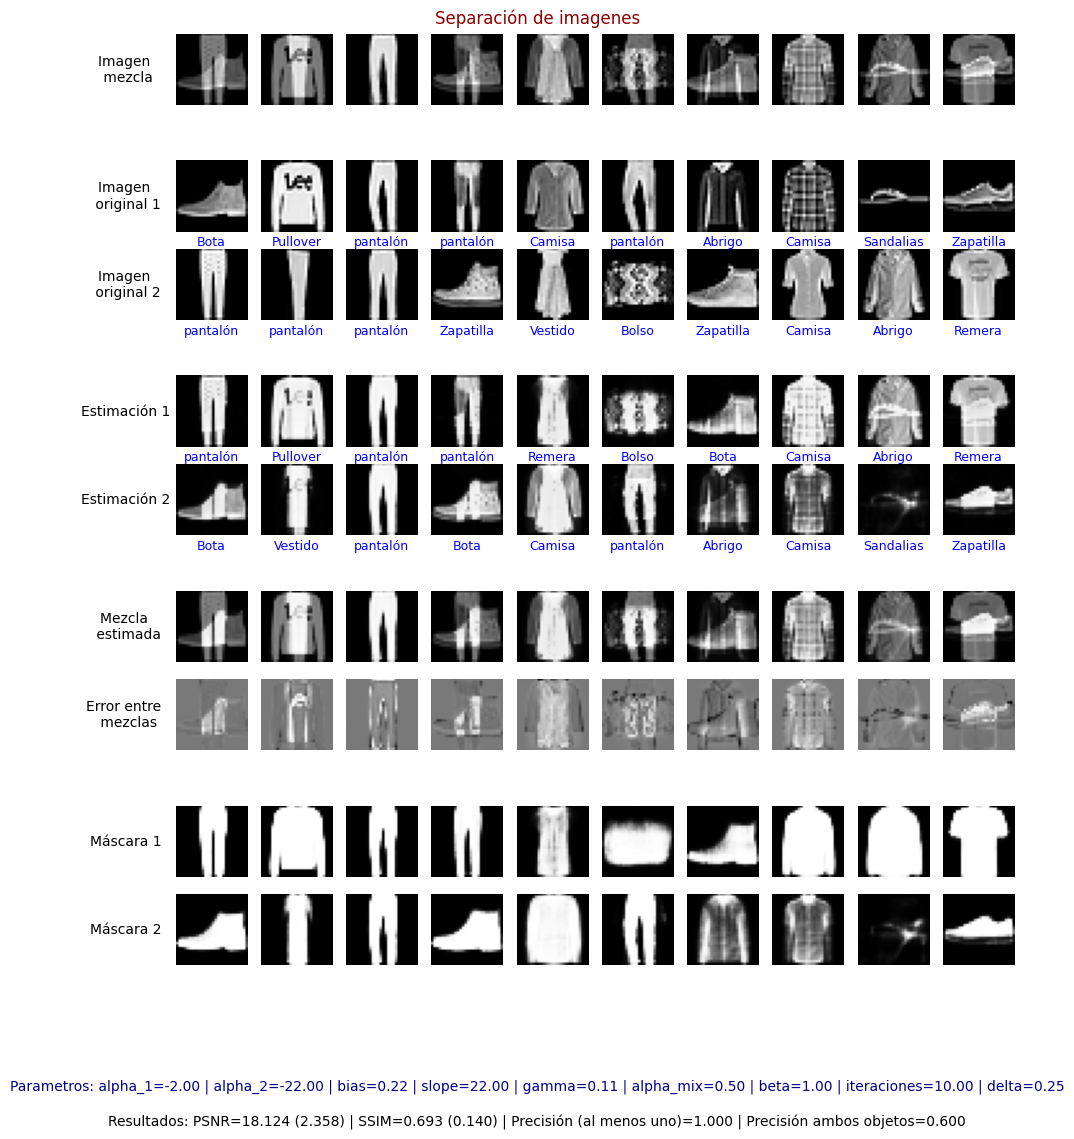

In [5]:
visual_dataset, visual_objective = "fashion", "acc_both"

visual_studies = {
    model: load_study(visual_dataset, visual_objective, model)
    for model in SEARCH_PARAMS
}
visual_inputs = load_inputs(visual_dataset)
visual_data = visual_inputs[0]
visual_batch = (
    visual_data["x_test"][:10], visual_data["x_test_1"][:10],
    visual_data["y_test"][:10], visual_data["y_test_1"][:10],
)

for model, study in visual_studies.items():
    print(f"{DATASETS[visual_dataset]} · {model} · {visual_objective} · {study.best_params}")
    evaluate(visual_inputs, model, visual_batch, study.best_params, SEED,
             COMPARISON_ITERATIONS, show_image=True)